In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

# the same two colours are used for the two passenger groups in every chart
colors = {'neutral or dissatisfied': '#C55A11', 'satisfied': '#1F4E79'}
print("Libraries imported successfully.")

Libraries imported successfully.


In [ ]:
from google.colab import files
uploaded = files.upload()
fname = list(uploaded.keys())[0]
print("Uploaded file:", fname)

Saving train.csv to train.csv
Uploaded file: train.csv


In [ ]:
df = pd.read_csv(fname)
dup_count = int(df.duplicated().sum())     # checked on the original file
print("Rows, Columns :", df.shape)
df.head()

Rows, Columns : (103904, 25)


,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,5,3,5,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,1,3,1,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,5,5,5,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,2,2,2,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,4,5,5,3,3,4,4,3,3,3,0,0.0,satisfied


In [ ]:
df = df.drop(columns=['Unnamed: 0', 'id'], errors='ignore')

# A 0/1 helper column (1 = satisfied) used to calculate satisfaction
# rates and correlations. The original text column is left unchanged.
df['satisfied_flag'] = (df['satisfaction'] == 'satisfied').astype(int)

print("Shape:", df.shape)
df.info()

Shape: (103904, 24)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 24 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             103904 non-null  object 
 1   Customer Type                      103904 non-null  object 
 2   Age                                103904 non-null  int64  
 3   Type of Travel                     103904 non-null  object 
 4   Class                              103904 non-null  object 
 5   Flight Distance                    103904 non-null  int64  
 6   Inflight wifi service              103904 non-null  int64  
 7   Departure/Arrival time convenient  103904 non-null  int64  
 8   Ease of Online booking             103904 non-null  int64  
 9   Gate location                      103904 non-null  int64  
 10  Food and drink                     103904 non-null  int64  
 11  Online boarding    

In [ ]:
print("Numeric columns:")
display(df.drop(columns='satisfied_flag').describe().T.round(2))
print("Text columns:")
display(df.describe(exclude='number').T)


Numeric columns:


,count,mean,std,min,25%,50%,75%,max
Age,103904.0,39.38,15.11,7.0,27.0,40.0,51.0,85.0
Flight Distance,103904.0,1189.45,997.15,31.0,414.0,843.0,1743.0,4983.0
Inflight wifi service,103904.0,2.73,1.33,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,103904.0,3.06,1.53,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,103904.0,2.76,1.40,0.0,2.0,3.0,4.0,5.0
Gate location,103904.0,2.98,1.28,0.0,2.0,3.0,4.0,5.0
Food and drink,103904.0,3.20,1.33,0.0,2.0,3.0,4.0,5.0
Online boarding,103904.0,3.25,1.35,0.0,2.0,3.0,4.0,5.0
Seat comfort,103904.0,3.44,1.32,0.0,2.0,4.0,5.0,5.0
Inflight entertainment,103904.0,3.36,1.33,0.0,2.0,4.0,4.0,5.0


Text columns:


,count,unique,top,freq
Gender,103904,2,Female,52727
Customer Type,103904,2,Loyal Customer,84923
Type of Travel,103904,2,Business travel,71655
Class,103904,3,Business,49665
satisfaction,103904,2,neutral or dissatisfied,58879


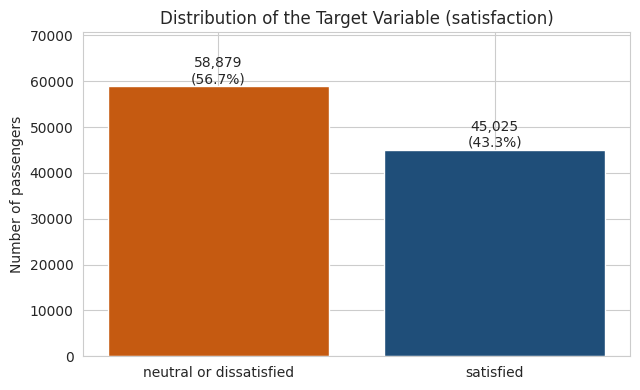

Columns with missing values:
Arrival Delay in Minutes    310
Duplicate rows in the original file: 0


In [ ]:
counts = df['satisfaction'].value_counts()
pct = (counts / len(df) * 100).round(1)

fig, ax = plt.subplots(figsize=(6.5, 4))
bars = ax.bar(counts.index, counts.values, color=[colors[k] for k in counts.index])
for b, p in zip(bars, pct):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(),
            f"{int(b.get_height()):,}\n({p}%)", ha='center', va='bottom')
ax.set_ylim(0, counts.max() * 1.2)
ax.set_title('Distribution of the Target Variable (satisfaction)')
ax.set_ylabel('Number of passengers')
plt.tight_layout()
plt.show()

missing = df.isnull().sum()
missing = missing[missing > 0]
if len(missing) > 0:
    print("Columns with missing values:")
    print(missing.to_string())
else:
    print("Columns with missing values: none")
print("Duplicate rows in the original file:", dup_count)

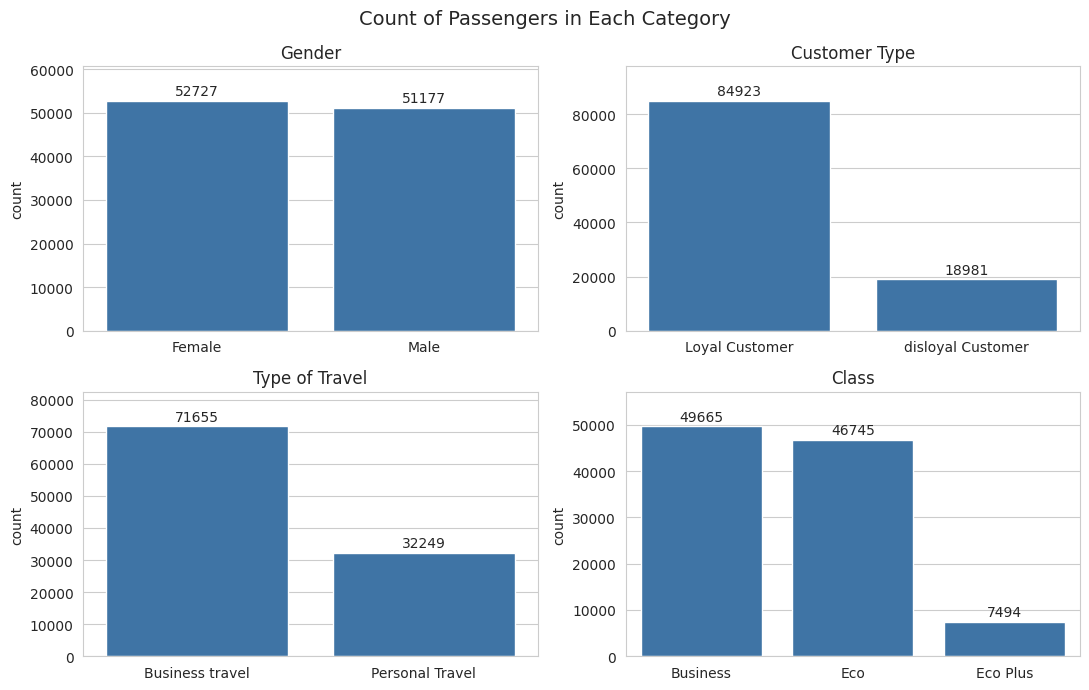

In [ ]:
cat_cols = ['Gender', 'Customer Type', 'Type of Travel', 'Class']

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.flat, cat_cols):
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, color='#2E75B6', ax=ax)
    for c in ax.containers:
        ax.bar_label(c, fmt='%d', padding=2)
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylim(0, df[col].value_counts().max() * 1.15)
plt.suptitle('Count of Passengers in Each Category', fontsize=14)
plt.tight_layout()
plt.show()

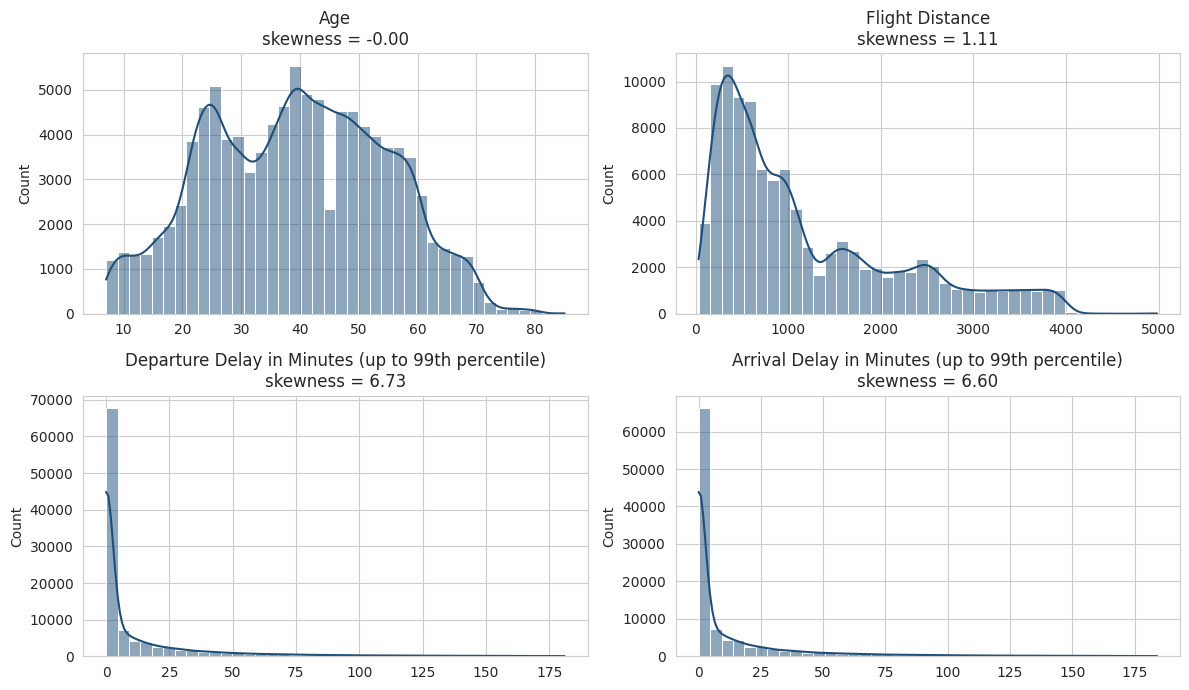

In [ ]:
num_cols = ['Age', 'Flight Distance', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.flat, num_cols):
    data = df[col].dropna()
    skew = data.skew()
    shown = data
    note = ''
    if 'Delay' in col:
        # the delays have a very long tail, so only values up to the
        # 99th percentile are drawn to keep the shape readable
        shown = data[data <= data.quantile(0.99)]
        note = ' (up to 99th percentile)'
    sns.histplot(shown, bins=40, kde=True, color='#1F4E79', ax=ax)
    ax.set_title(f"{col}{note}\nskewness = {skew:.2f}")
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

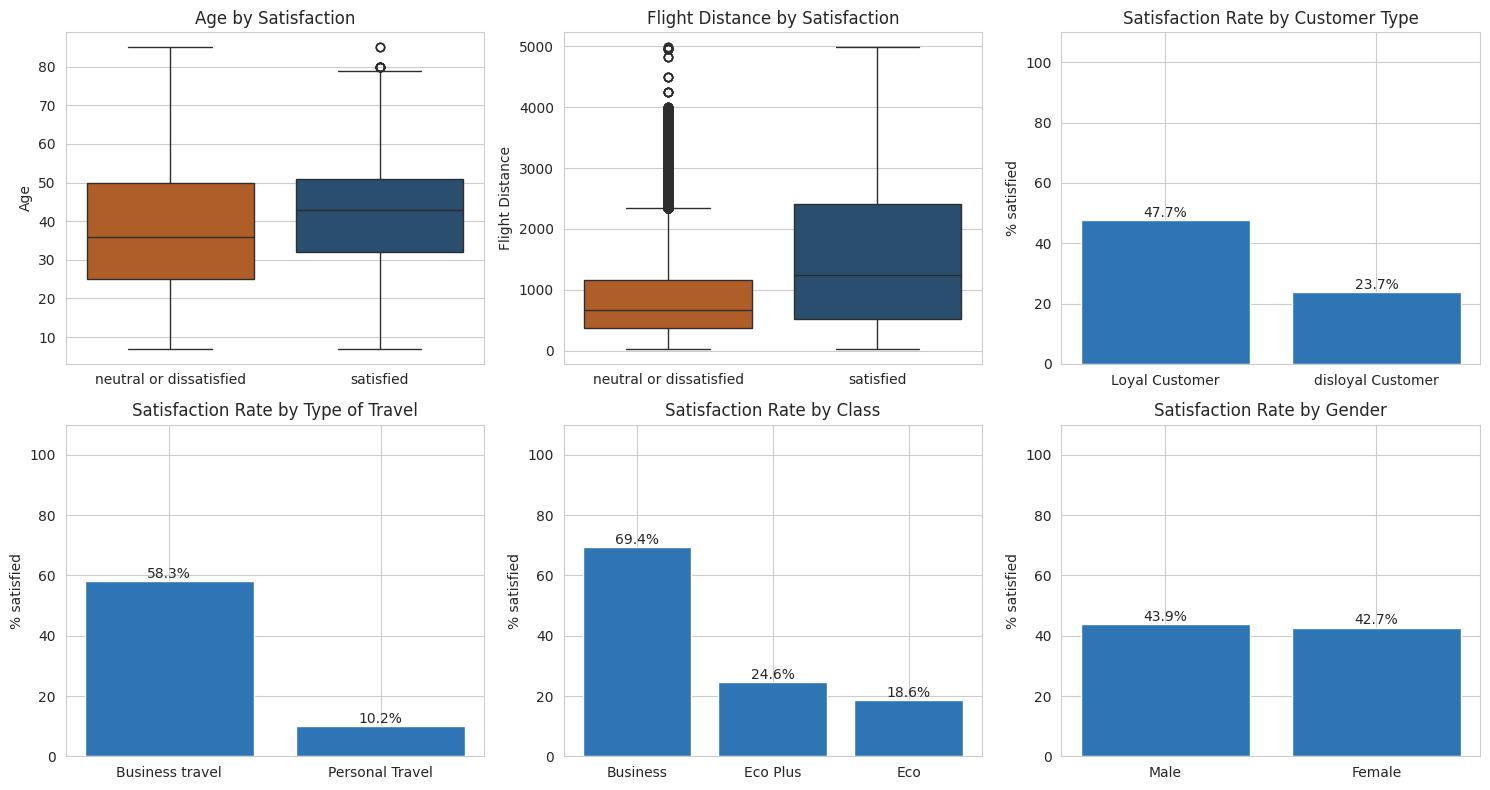

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# top row: numeric columns by satisfaction
for ax, col in zip(axes[0, :2], ['Age', 'Flight Distance']):
    sns.boxplot(data=df, x='satisfaction', y=col, hue='satisfaction',
                palette=colors, legend=False, ax=ax)
    ax.set_title(f"{col} by Satisfaction")
    ax.set_xlabel('')

# remaining panels: satisfaction rate (%) for each category
rate_cols = ['Customer Type', 'Type of Travel', 'Class', 'Gender']
for ax, col in zip([axes[0, 2], axes[1, 0], axes[1, 1], axes[1, 2]], rate_cols):
    rate = (df.groupby(col)['satisfied_flag'].mean() * 100).sort_values(ascending=False)
    ax.bar(rate.index, rate.values, color='#2E75B6')
    for i, v in enumerate(rate.values):
        ax.text(i, v + 1, f"{v:.1f}%", ha='center')
    ax.set_ylim(0, 110)
    ax.set_title(f"Satisfaction Rate by {col}")
    ax.set_ylabel('% satisfied')
plt.tight_layout()
plt.show()

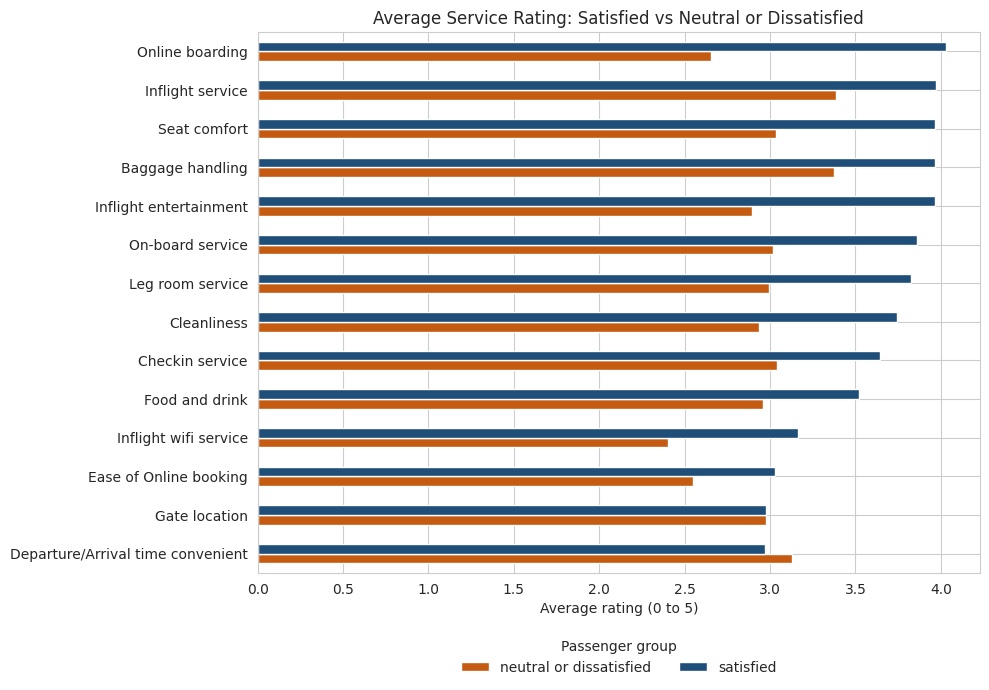

In [ ]:
rating_cols = ['Inflight wifi service', 'Departure/Arrival time convenient',
               'Ease of Online booking', 'Gate location', 'Food and drink',
               'Online boarding', 'Seat comfort', 'Inflight entertainment',
               'On-board service', 'Leg room service', 'Baggage handling',
               'Checkin service', 'Inflight service', 'Cleanliness']

avg = df.groupby('satisfaction')[rating_cols].mean().T
avg = avg.sort_values('satisfied')

ax = avg.plot(kind='barh', figsize=(10, 7),
             color=[colors['neutral or dissatisfied'], colors['satisfied']])
ax.set_title('Average Service Rating: Satisfied vs Neutral or Dissatisfied')
ax.set_xlabel('Average rating (0 to 5)')
ax.legend(title='Passenger group', loc='upper center',
          bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

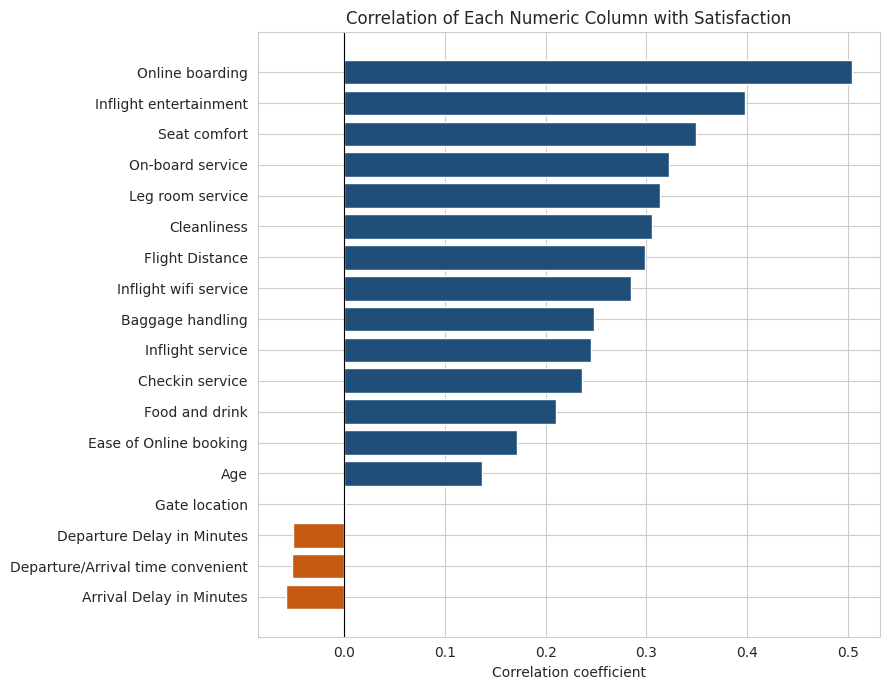

In [ ]:
corr_target = (df.select_dtypes(include='number').corr()['satisfied_flag']
                 .drop('satisfied_flag').sort_values())

plt.figure(figsize=(9, 7))
plt.barh(corr_target.index, corr_target.values,
         color=['#C55A11' if v < 0 else '#1F4E79' for v in corr_target.values])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Correlation of Each Numeric Column with Satisfaction')
plt.xlabel('Correlation coefficient')
plt.tight_layout()
plt.show()

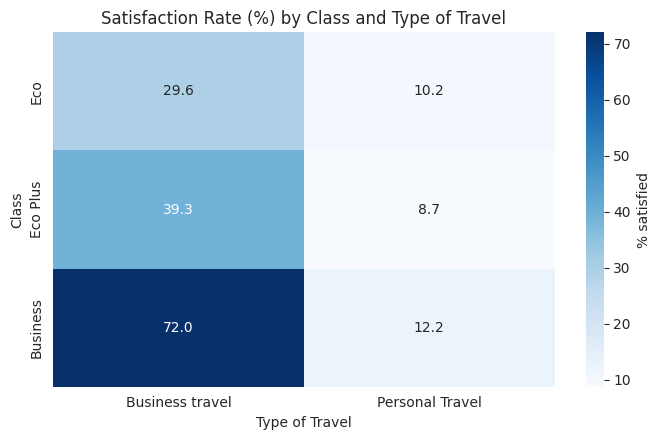

In [ ]:
pivot = (df.pivot_table(values='satisfied_flag', index='Class',
                        columns='Type of Travel', aggfunc='mean') * 100)
pivot = pivot.reindex(['Eco', 'Eco Plus', 'Business'])

plt.figure(figsize=(7, 4.5))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='Blues', cbar_kws={'label': '% satisfied'})
plt.title('Satisfaction Rate (%) by Class and Type of Travel')
plt.tight_layout()
plt.show()

In [ ]:
overall = df['satisfied_flag'].mean() * 100
print(f"Overall satisfaction rate: {overall:.1f}%\n")

for col in ['Class', 'Type of Travel', 'Customer Type', 'Gender']:
    r = (df.groupby(col)['satisfied_flag'].mean() * 100).round(1).sort_values(ascending=False)
    print(f"{col:15s}: " + ",  ".join(f"{k} {v}%" for k, v in r.items()))

print()
c = (df.select_dtypes(include='number').corr()['satisfied_flag']
       .drop('satisfied_flag').sort_values(ascending=False))
print("Strongest positive correlation with satisfaction:")
for k, v in c.head(3).items():
    print(f"   {k}: {v:.2f}")
print("Strongest negative correlation with satisfaction:")
for k, v in c.tail(3).items():
    print(f"   {k}: {v:.2f}")

print()
for col in ['Departure Delay in Minutes', 'Arrival Delay in Minutes']:
    print(f"Skewness of {col}: {df[col].skew():.2f}")


Overall satisfaction rate: 43.3%

Class          : Business 69.4%,  Eco Plus 24.6%,  Eco 18.6%
Type of Travel : Business travel 58.3%,  Personal Travel 10.2%
Customer Type  : Loyal Customer 47.7%,  disloyal Customer 23.7%
Gender         : Male 43.9%,  Female 42.7%

Strongest positive correlation with satisfaction:
   Online boarding: 0.50
   Inflight entertainment: 0.40
   Seat comfort: 0.35
Strongest negative correlation with satisfaction:
   Departure Delay in Minutes: -0.05
   Departure/Arrival time convenient: -0.05
   Arrival Delay in Minutes: -0.06

Skewness of Departure Delay in Minutes: 6.73
Skewness of Arrival Delay in Minutes: 6.60
